In [29]:
import jax
import jax.numpy as jnp
from jax import random, grad, jit, vmap
import optax
import wandb
import numpy as np
import matplotlib.pyplot as plt

# MLP and MG_NN classes as provided by the user
class MLP:
    """Simple MLP for approximating functions without Flax, adapted for variable input dimensions."""
    def __init__(self, input_dim, hidden_dims=(64, 64), activation=jnp.tanh, lb=None, ub=None, normalize_input=True, seed=0):
        self.input_dim = input_dim
        self.hidden_dims = hidden_dims
        self.activation = activation
        self.normalize_input = normalize_input
        if normalize_input:
            self.lb = lb if lb is not None else jnp.zeros((input_dim,))
            self.ub = ub if ub is not None else jnp.ones((input_dim,))
        self.key = random.PRNGKey(seed)
        self.params = self.initialize_params()

    def initialize_params(self):
        params = []
        num_layers = len(self.hidden_dims) + 1
        keys = random.split(self.key, num_layers)
        a = jnp.sqrt(0.01)
        params.append(a)
        layers = [self.input_dim] + list(self.hidden_dims) + [1]
        for l in range(num_layers):
            W = self.xavier_init((layers[l], layers[l+1]), keys[l])
            b = jnp.zeros((layers[l+1],), dtype=jnp.float32)
            params.append((W, b))
        return params

    def xavier_init(self, size, key):
        in_dim, out_dim = size
        xavier_stddev = jnp.sqrt(2 / (in_dim + out_dim))
        return random.truncated_normal(key, -2, 2, shape=(out_dim, in_dim), dtype=jnp.float32) * xavier_stddev

    def forward(self, params, x, extra_output=False):
        if self.normalize_input:
            x = 2.0 * (x - self.lb) / (self.ub - self.lb) - 1.0
        a = params[0]
        for l in range(1, len(params) - 1):
            W, b = params[l]
            x = jnp.dot(x, W.T) + b
            x = self.activation(10.0 * a * x)
        W, b = params[-1]
        y = jnp.dot(x, W.T) + b
        out_wo_layer = x
        out = jnp.squeeze(y)
        if extra_output:
            return out, out_wo_layer
        else:
            return out

    def __call__(self, params, x):
        return self.forward(params, x)

class MG_NN:
    """Multi-Grade Neural Network for regression, stacking shallow MLPs."""
    def __init__(self, input_dim, hidden_dims_list, activation=jnp.tanh, lb=None, ub=None, seed=0):
        self.input_dim = input_dim
        self.hidden_dims_list = hidden_dims_list
        self.activation = activation
        self.lb = lb
        self.ub = ub
        self.seed = seed
        self.mlps = []
        self.current_grade = 0

    def add_grade(self):
        if self.current_grade == 0:
            mlp = MLP(input_dim=self.input_dim,
                      hidden_dims=self.hidden_dims_list[self.current_grade],
                      activation=self.activation,
                      lb=self.lb,
                      ub=self.ub,
                      normalize_input=True,
                      seed=self.seed)
        else:
            last_hidden_dim = self.hidden_dims_list[self.current_grade - 1][-1]
            mlp = MLP(input_dim=last_hidden_dim,
                      hidden_dims=self.hidden_dims_list[self.current_grade],
                      activation=self.activation,
                      normalize_input=False,
                      seed=self.seed)
        self.mlps.append(mlp)
        self.current_grade += 1

    def forward(self, x):
        temp = x
        sum_out = 0
        for mlp in self.mlps:
            out, out_wo_layer = mlp.forward(mlp.params, temp, extra_output=True)
            sum_out += out
            temp = out_wo_layer
        return sum_out


In [30]:
# Define the Burgers equation residual

def burgers_residual(u, X):
    nu = 0.01 / jnp.pi
    u_val = u(X)
    grad_u = grad(u, 0)(X)
    u_x = grad_u[0]
    u_t = grad_u[1]
    u_xx = grad(lambda X: grad(u, 0)(X)[0], 0)(X)[0]
    return u_t + u_val * u_x - nu * u_xx

# Initial condition
def initial_condition(x):
    return -jnp.sin(jnp.pi * x)

# Define the boundary conditions
def boundary_condition(t):
    return 0.0

# Helper function for second stage forward pass
def forward_with_params(mg_nn, params_list, x):
    temp = x
    sum_out = 0
    for i, mlp in enumerate(mg_nn.mlps):
        params = params_list[i]
        out, out_wo_layer = mlp.forward(params, temp, extra_output=True)
        sum_out += out
        temp = out_wo_layer
    return sum_out


# Loss function for the first stage
def loss_fn(params, mlp, X_input, mlp_index, mg_nn):
    def get_total_u(X):
        temp = X
        sum_out = 0
        for i in range(mlp_index-1):
            out, out_wo_layer = mg_nn.mlps[i].forward(mg_nn.mlps[i].params, temp, extra_output=True)
            sum_out += out
            temp = out_wo_layer
        out_current = mlp.forward(params, temp)
        return sum_out + out_current

    total_u = lambda X: get_total_u(X)

    # PDE residual loss
    residual = vmap(burgers_residual, (None, 0))(total_u, X_input)
    loss_pde = jnp.mean(residual**2)

    # Generate IC and BC points (assuming X_input has shape [N, 2])
    N = 200  # Number of points for IC and BC
    x = jnp.linspace(-1, 1, N)
    t = jnp.linspace(0, 1, N)
    
    # Initial condition loss
    t_ic = jnp.zeros_like(x)
    X_ic = jnp.stack([x, t_ic], axis=1)
    u_ic_pred = vmap(total_u)(X_ic)
    u_ic_true = initial_condition(x)
    loss_ic = jnp.mean((u_ic_pred - u_ic_true)**2)

    # Boundary condition loss
    x_lb = -1.0 * jnp.ones_like(t)
    x_ub = 1.0 * jnp.ones_like(t)
    X_lb = jnp.stack([x_lb, t], axis=1)
    X_ub = jnp.stack([x_ub, t], axis=1)
    u_lb_pred = vmap(total_u)(X_lb)
    u_ub_pred = vmap(total_u)(X_ub)
    loss_bc = jnp.mean(u_lb_pred**2) + jnp.mean(u_ub_pred**2)

    return loss_pde + loss_ic + loss_bc
    # return loss_ic + loss_bc

# Loss function for the second stage
def loss_fn_second_stage(params_last_k, mg_nn, X_input, k):
    n = len(mg_nn.mlps)
    m = n - k + 1
    fixed_params = [mg_nn.mlps[i].params for i in range(m-1)] if m > 1 else []
    params_list = fixed_params + list(params_last_k)

    def total_u(X):
        return forward_with_params(mg_nn, params_list, X)

    residual = vmap(burgers_residual, (None, 0))(total_u, X_input)
    loss_pde = jnp.mean(residual**2)

    N = 200
    x = jnp.linspace(-1, 1, N)
    t = jnp.linspace(0, 1, N)
    t_ic = jnp.zeros_like(x)
    X_ic = jnp.stack([x, t_ic], axis=1)
    u_ic_pred = vmap(total_u)(X_ic)
    u_ic_true = initial_condition(x)
    loss_ic = jnp.mean((u_ic_pred - u_ic_true)**2)

    x_lb = -1.0 * jnp.ones_like(t)
    x_ub = 1.0 * jnp.ones_like(t)
    X_lb = jnp.stack([x_lb, t], axis=1)
    X_ub = jnp.stack([x_ub, t], axis=1)
    u_lb_pred = vmap(total_u)(X_lb)
    u_ub_pred = vmap(total_u)(X_ub)
    loss_bc = jnp.mean(u_lb_pred**2) + jnp.mean(u_ub_pred**2)

    return loss_pde + loss_ic + loss_bc

In [31]:
# Training function for the first stage
def train_grade(mg_nn, mlp_index, X_input, epochs, init_lr, decay_rate, global_step):
    mlp = mg_nn.mlps[mlp_index-1]
    params = mlp.params
    lr = optax.exponential_decay(
        init_value=init_lr,
        transition_steps=epochs,
        decay_rate=decay_rate,
        )
    optimizer = optax.adam(lr)
    opt_state = optimizer.init(params)

    @jit
    def step(params, opt_state):
        grads = grad(loss_fn)(params, mlp, X_input, mlp_index, mg_nn)
        updates, opt_state = optimizer.update(grads, opt_state)
        params = optax.apply_updates(params, updates)
        return params, opt_state

    for epoch in range(epochs):
        mlp.params, opt_state = step(mlp.params, opt_state)
        if epoch % 100 == 0:
            loss = loss_fn(mlp.params, mlp, X_input, mlp_index, mg_nn)
            print(f"Grade {mlp_index}, Epoch {epoch}, Loss: {loss:.8f}")
            wandb.log({f"grade_{mlp_index}_loss": loss.item(), "step": global_step + epoch})
    return mlp.params

# Main function to solve Burgers equation with MG_NN
def solve_burgers(total_grade=3, k=2, dims_list=[(40, 40), (40, 40), (40, 40)], decay_rate=1e-4, 
                  epochs=None, lrs=None, 
                  epoch_2ndstage=50000, lr_2ndstage=2e-4):
    global_step = 0
    # Initialize wandb
    wandb.init(project="burgers_mgdl", name=f"total_grade_{total_grade}_k_{k}", config={
        "total_grade": total_grade,
        "k": k,
        "hidden_dims_list": dims_list,
        "lrs": lrs,
        "epochs": epochs,
        "lr_2ndstage": lr_2ndstage,
        "epoch_2ndstage": epoch_2ndstage,
        "decay_rate": decay_rate
    })
    
    X_grid = jnp.stack(jnp.meshgrid(jnp.linspace(-1, 1, 100), jnp.linspace(0, 1, 100)), axis=-1).reshape(-1, 2)
    lb = jnp.array([-1.0, 0.0])
    ub = jnp.array([1.0, 1.0])
    hidden_dims_list = dims_list
    activation = jnp.tanh
    seed = 0
    
    lrs = [1e-3] * total_grade if lrs==None else lrs
    epochs = [50000] * total_grade if epochs==None else epochs

    N = 200
    x = jnp.linspace(-1, 1, N)
    t = jnp.linspace(0, 1, N)
    X, T = jnp.meshgrid(x, t)
    X_flat = X.flatten()
    T_flat = T.flatten()
    X_input = jnp.stack([X_flat, T_flat], axis=-1)

    mg_nn = MG_NN(input_dim=2, hidden_dims_list=hidden_dims_list, activation=activation, lb=lb, ub=ub, seed=seed)

    # Stage 1: Train each grade sequentially
    for mlp_index in range(1, total_grade+1):
        mg_nn.add_grade()
        print(f"\nTraining Grade {mg_nn.current_grade}")
        train_grade(mg_nn, mlp_index, X_input, epochs[mlp_index-1], lrs[mlp_index-1], decay_rate, global_step)
        global_step += epochs[mlp_index-1]

    # Stage 2: Unfreeze and retrain the last k grades
    if k > 0 and k <= total_grade:
        print(f"\nSecond stage: Unfreezing last {k} grades")
        params_last_k = [mlp.params for mlp in mg_nn.mlps[-k:]]
        lr = optax.exponential_decay(
            init_value=lr_2ndstage,
            transition_steps=epoch_2ndstage,
            decay_rate=decay_rate,
            )
        optimizer = optax.adam(lr)
        opt_state = optimizer.init(params_last_k)

        @jit
        def step(params_last_k, opt_state):
            grads = grad(loss_fn_second_stage)(params_last_k, mg_nn, X_input, k)
            updates, opt_state = optimizer.update(grads, opt_state)
            params_last_k = optax.apply_updates(params_last_k, updates)
            return params_last_k, opt_state

        for epoch in range(epoch_2ndstage):
            params_last_k, opt_state = step(params_last_k, opt_state)
            if epoch % 100 == 0:
                loss = loss_fn_second_stage(params_last_k, mg_nn, X_input, k)
                print(f"Second stage, Epoch {epoch}, Loss: {loss:.8f}")
                wandb.log({"second_stage_loss": loss.item(), "step": global_step + epoch})
        global_step += epoch_2ndstage

        # Update the MLP parameters with the refined values
        for mlp, params in zip(mg_nn.mlps[-k:], params_last_k):
            mlp.params = params

    # Final prediction
    u_pred = mg_nn.forward(X_grid)
    print("\nTraining completed. Final prediction shape:", u_pred.shape)

    # Plotting
    x = np.linspace(-1, 1, 100)
    t = np.linspace(0, 1, 100)
    X, T = np.meshgrid(x, t)
    plt.contourf(X, T, u_pred.reshape(100, 100), levels=50, cmap='jet')
    plt.colorbar()
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title('Solution to Burgers Equation')
    plt.show()

    # Finish wandb run
    wandb.finish()
    return u_pred.reshape(100, 100)


wandb: Currently logged in as: haoli1 to https://api.wandb.ai. Use `wandb login --relogin` to force relogin



Training Grade 1
Grade 1, Epoch 0, Loss: 0.460077
Grade 1, Epoch 100, Loss: 0.167080
Grade 1, Epoch 200, Loss: 0.141530
Grade 1, Epoch 300, Loss: 0.113209
Grade 1, Epoch 400, Loss: 0.098886
Grade 1, Epoch 500, Loss: 0.092227
Grade 1, Epoch 600, Loss: 0.088440
Grade 1, Epoch 700, Loss: 0.085038
Grade 1, Epoch 800, Loss: 0.083810
Grade 1, Epoch 900, Loss: 0.081251
Grade 1, Epoch 1000, Loss: 0.079030
Grade 1, Epoch 1100, Loss: 0.076637
Grade 1, Epoch 1200, Loss: 0.072978
Grade 1, Epoch 1300, Loss: 0.066856
Grade 1, Epoch 1400, Loss: 0.058137
Grade 1, Epoch 1500, Loss: 0.051780
Grade 1, Epoch 1600, Loss: 0.044415
Grade 1, Epoch 1700, Loss: 0.042479
Grade 1, Epoch 1800, Loss: 0.043580
Grade 1, Epoch 1900, Loss: 0.034907
Grade 1, Epoch 2000, Loss: 0.032860
Grade 1, Epoch 2100, Loss: 0.031522
Grade 1, Epoch 2200, Loss: 0.029545
Grade 1, Epoch 2300, Loss: 0.028151
Grade 1, Epoch 2400, Loss: 0.026759
Grade 1, Epoch 2500, Loss: 0.027434
Grade 1, Epoch 2600, Loss: 0.023863
Grade 1, Epoch 2700, L

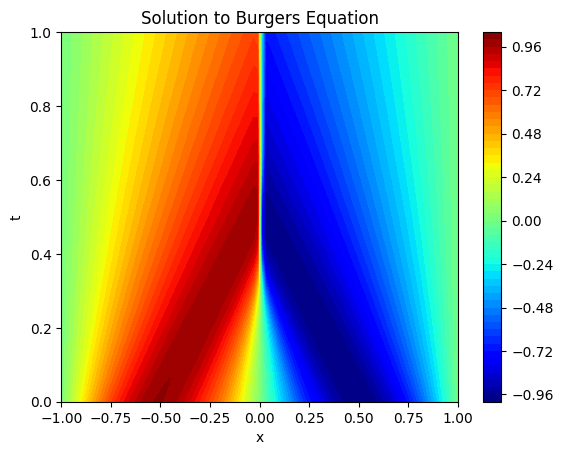

grade_1_loss,█▇▆▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_2_loss,█▅▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_3_loss,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_4_loss,█▃▃▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
second_stage_loss,█████▇▇▆▆▆▅▅▅▄▄▃▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇███
grade_1_loss,0.00116
grade_2_loss,0.00106
grade_3_loss,0.00105
grade_4_loss,0.00105
second_stage_loss,0.00033


In [32]:
u_pred = solve_burgers(total_grade=4, k=3, 
                       dims_list=[(40, 40), (40, 40), (40, 40), (40, 40)],
                       lrs=[1e-3, 1e-3, 1e-3, 1e-3])

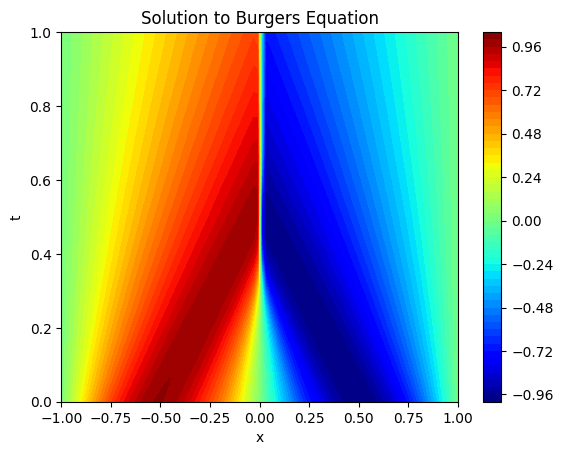

In [28]:
import matplotlib.pyplot as plt
import numpy as np

def plot_solution(u):
    """
    Plots the solution to the Burgers equation using a contour plot.

    Args:
        u_pred (jax.numpy.ndarray or numpy.ndarray): 2D array of shape (100, 100) representing the solution.
    """
    # Generate spatial and temporal grids
    x = np.linspace(-1, 1, 100)
    t = np.linspace(0, 1, 100)
    X, T = np.meshgrid(x, t)
    
    # Plot the contour
    plt.contourf(X, T, u, levels=50, cmap='jet')
    plt.colorbar()
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title('Solution to Burgers Equation')
    plt.show()
plot_solution(u_pred)

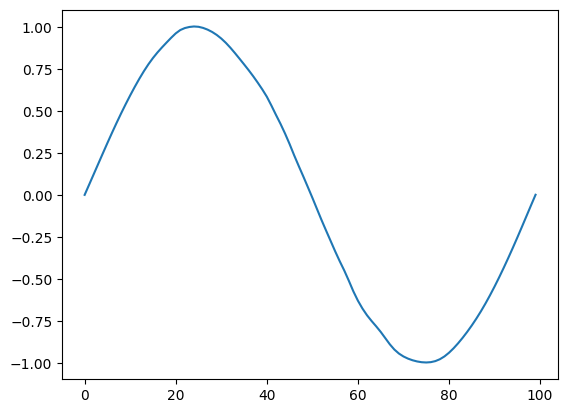

In [37]:
plt.plot(u_pred[0,:])

In [36]:
import jax
import jax.numpy as jnp
from jax import random, grad, jit, vmap
import optax
import wandb
import numpy as np
import matplotlib.pyplot as plt

# Classical PINN with 8 hidden layers
class PINN:
    """Classical PINN with multiple hidden layers."""
    def __init__(self, input_dim, hidden_layers, activation=jnp.tanh, lb=None, ub=None, seed=0):
        self.input_dim = input_dim
        self.hidden_layers = hidden_layers
        self.activation = activation
        self.lb = lb if lb is not None else jnp.zeros((input_dim,))
        self.ub = ub if ub is not None else jnp.ones((input_dim,))
        self.key = random.PRNGKey(seed)
        self.params = self.initialize_params()

    def initialize_params(self):
        params = []
        layers = [self.input_dim] + self.hidden_layers + [1]
        for l in range(len(layers) - 1):
            W = self.xavier_init((layers[l], layers[l+1]), self.key)
            b = jnp.zeros((layers[l+1],), dtype=jnp.float32)
            params.append((W, b))
            self.key, _ = random.split(self.key)
        return params

    def xavier_init(self, size, key):
        in_dim, out_dim = size
        xavier_stddev = jnp.sqrt(2 / (in_dim + out_dim))
        return random.truncated_normal(key, -2, 2, shape=(out_dim, in_dim), dtype=jnp.float32) * xavier_stddev

    def forward(self, params, x):
        x = 2.0 * (x - self.lb) / (self.ub - self.lb) - 1.0  # Normalize input
        for W, b in params[:-1]:
            x = self.activation(jnp.dot(x, W.T) + b)
        W, b = params[-1]
        y = jnp.dot(x, W.T) + b
        return jnp.squeeze(y)

# Define the Burgers equation residual for PINN
def burgers_residual_pinn(u, X):
    nu = 0.01 / jnp.pi  # Viscosity
    u_val = u(X)
    grad_u = grad(u, 0)(X)
    u_x = grad_u[0]
    u_t = grad_u[1]
    u_xx = grad(lambda X: grad(u, 0)(X)[0], 0)(X)[0]
    return u_t + u_val * u_x - nu * u_xx

# Initial condition
def initial_condition(x):
    return -jnp.sin(jnp.pi * x)

# Loss function for PINN
def loss_fn_pinn(params, pinn, X_input):
    u_pred = lambda X: pinn.forward(params, X)
    residual = vmap(burgers_residual_pinn, (None, 0))(u_pred, X_input)
    loss_pde = jnp.mean(residual**2)

    N = 200
    x = jnp.linspace(-1, 1, N)
    t = jnp.linspace(0, 1, N)
    t_ic = jnp.zeros_like(x)
    X_ic = jnp.stack([x, t_ic], axis=1)
    u_ic_pred = vmap(u_pred)(X_ic)
    u_ic_true = initial_condition(x)
    loss_ic = jnp.mean((u_ic_pred - u_ic_true)**2)

    x_lb = -1.0 * jnp.ones_like(t)
    x_ub = 1.0 * jnp.ones_like(t)
    X_lb = jnp.stack([x_lb, t], axis=1)
    X_ub = jnp.stack([x_ub, t], axis=1)
    u_lb_pred = vmap(u_pred)(X_lb)
    u_ub_pred = vmap(u_pred)(X_ub)
    loss_bc = jnp.mean(u_lb_pred**2) + jnp.mean(u_ub_pred**2)

    return loss_pde + loss_ic + loss_bc

# Training function for PINN
def train_pinn(pinn, X_input, epochs, init_lr, decay_rate=1e-4):
    params = pinn.params
    lr = optax.exponential_decay(init_value=init_lr, transition_steps=epochs, decay_rate=decay_rate)
    optimizer = optax.adam(lr)
    opt_state = optimizer.init(params)

    @jit
    def step(params, opt_state):
        grads = grad(loss_fn_pinn)(params, pinn, X_input)
        updates, opt_state = optimizer.update(grads, opt_state)
        params = optax.apply_updates(params, updates)
        return params, opt_state

    for epoch in range(epochs):
        params, opt_state = step(params, opt_state)
        if epoch % 100 == 0:
            loss = loss_fn_pinn(params, pinn, X_input)
            print(f"PINN, Epoch {epoch}, Loss: {loss:.6f}")
            wandb.log({"pinn_loss": loss.item()})

    pinn.params = params
    return params

# Main function for PINN
def solve_burgers_pinn(hidden_layers=[40]*8, epochs=200000, init_lr=1e-3, decay_rate=1e-4):
    # Initialize wandb for logging
    wandb.init(project="burgers_pinn", name="pinn_8_layers", config={
        "hidden_layers": hidden_layers,
        "epochs": epochs,
        "init_lr": init_lr,
        "decay_rate": decay_rate
    })

    lb = jnp.array([-1.0, 0.0])  # Lower bounds (x, t)
    ub = jnp.array([1.0, 1.0])   # Upper bounds (x, t)
    seed = 0

    # Training data points
    N = 200
    x = jnp.linspace(-1, 1, N)
    t = jnp.linspace(0, 1, N)
    X, T = jnp.meshgrid(x, t)
    X_flat = X.flatten()
    T_flat = T.flatten()
    X_input = jnp.stack([X_flat, T_flat], axis=-1)

    # Initialize and train PINN
    pinn = PINN(input_dim=2, hidden_layers=hidden_layers, lb=lb, ub=ub, seed=seed)
    train_pinn(pinn, X_input, epochs, init_lr, decay_rate)

    # Prediction for plotting
    X_grid = jnp.stack(jnp.meshgrid(jnp.linspace(-1, 1, 100), jnp.linspace(0, 1, 100)), axis=-1).reshape(-1, 2)
    u_pred = vmap(lambda X: pinn.forward(pinn.params, X))(X_grid)

    # Plotting
    x = np.linspace(-1, 1, 100)
    t = np.linspace(0, 1, 100)
    X, T = np.meshgrid(x, t)
    plt.contourf(X, T, u_pred.reshape(100, 100), levels=50, cmap='jet')
    plt.colorbar()
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title('PINN Solution to Burgers Equation')
    plt.show()

    wandb.finish()
    return u_pred.reshape(100, 100)

if __name__ == "__main__":
    u_pred_pinn = solve_burgers_pinn()

pinn_loss,█▃▂▁▁
pinn_loss,0.10043


PINN, Epoch 0, Loss: 0.505045
PINN, Epoch 100, Loss: 0.189382
PINN, Epoch 200, Loss: 0.152520
PINN, Epoch 300, Loss: 0.126926
PINN, Epoch 400, Loss: 0.100433
PINN, Epoch 500, Loss: 0.088430
PINN, Epoch 600, Loss: 0.078168
PINN, Epoch 700, Loss: 0.066146
PINN, Epoch 800, Loss: 0.064283
PINN, Epoch 900, Loss: 0.043815
PINN, Epoch 1000, Loss: 0.080291
PINN, Epoch 1100, Loss: 0.056552
PINN, Epoch 1200, Loss: 0.015711
PINN, Epoch 1300, Loss: 0.011580
PINN, Epoch 1400, Loss: 0.010857
PINN, Epoch 1500, Loss: 0.007145
PINN, Epoch 1600, Loss: 0.006868
PINN, Epoch 1700, Loss: 0.005296
PINN, Epoch 1800, Loss: 0.005776
PINN, Epoch 1900, Loss: 0.004181
PINN, Epoch 2000, Loss: 0.036291
PINN, Epoch 2100, Loss: 0.004371
PINN, Epoch 2200, Loss: 0.003753
PINN, Epoch 2300, Loss: 0.003412
PINN, Epoch 2400, Loss: 0.003133
PINN, Epoch 2500, Loss: 0.002893
PINN, Epoch 2600, Loss: 0.002737
PINN, Epoch 2700, Loss: 0.002670
PINN, Epoch 2800, Loss: 0.002820
PINN, Epoch 2900, Loss: 0.002240
PINN, Epoch 3000, Loss

KeyboardInterrupt: 

wandb: WARNING Fatal error while uploading data. Some run data will not be synced, but it will still be written to disk. Use `wandb sync` at the end of the run to try uploading.


cpu
(100,)
[-1.         -0.97979796 -0.9595959  -0.939394   -0.91919196 -0.8989899
 -0.8787879  -0.85858583 -0.8383838  -0.81818175 -0.79797983 -0.7777778
 -0.75757575 -0.7373737  -0.71717167 -0.69696975 -0.6767677  -0.65656567
 -0.6363636  -0.6161616  -0.59595966 -0.5757575  -0.5555556  -0.53535354
 -0.5151515  -0.49494955 -0.47474745 -0.45454547 -0.43434346 -0.41414142
 -0.39393938 -0.37373737 -0.35353538 -0.33333328 -0.31313133 -0.2929293
 -0.27272725 -0.2525253  -0.2323232  -0.21212122 -0.19191921 -0.17171717
 -0.15151513 -0.13131312 -0.11111113 -0.09090903 -0.07070708 -0.05050504
 -0.030303   -0.01010105  0.01010096  0.030303    0.05050504  0.07070708
  0.09090912  0.11111116  0.13131309  0.15151513  0.17171717  0.19191921
  0.21212125  0.23232329  0.2525252   0.27272725  0.2929293   0.31313133
  0.33333337  0.3535353   0.37373734  0.39393938  0.41414142  0.43434346
  0.4545455   0.47474742  0.49494946  0.5151515   0.53535354  0.5555556
  0.5757576   0.59595954  0.6161616   0.6363